In [1]:
from manim import *

video_scene = " -v WARNING --disable_caching srt_Scene"
image_scene = f" -v WARNING --disable_caching -r {2*427},{2*240}  -s srt_Scene"

In [100]:
class Clock(Mobject):
	def __init__(self, clock_center = np.array([0, 0, 0]), clock_radius = 1, **kwargs):
		super().__init__(**kwargs)

		self.clock_center = clock_center
		self.clock_radius = clock_radius

		clock_circle = Circle(radius = self.clock_radius, color = BLACK).move_to(self.clock_center)
		self.add(clock_circle)

		clock_tick_line_group = VGroup()
		for i in range(12):
			clock_tick_line = Line(start = clock_center+clock_radius*UP, end = clock_center+clock_radius*UP*0.8, color = BLACK).rotate(angle = -i * 2*PI / 12, about_point = clock_center)
			clock_tick_line_group.add(clock_tick_line)
		self.add(clock_tick_line_group)


	def get_time(self, time = 0):
		time_group = VGroup()

		time_pointer = Line(
			start = self.clock_center, end = self.clock_center+self.clock_radius*0.7*UP, color = RED, stroke_width = 6
			).add_tip(tip_width = 0.0655, tip_length = 0.1).rotate(angle = -time * 2*PI / 60, about_point = self.clock_center)
		time_group.add(time_pointer)


		time_center_circle = Circle(radius = 0.025, color = GRAY, fill_color = GRAY).move_to(self.clock_center)
		time_group.add(time_center_circle)
		return time_group


class SpaceShip(Mobject):
	def __init__(self, ship_center = np.array([0, 0, 0]), ship_width = 6, ship_height = 2, **kwargs):
		super().__init__(**kwargs)

		self.ship_center = ship_center
		self.ship_width = ship_width
		self.ship_height = ship_height

		spaceship_group = VGroup()
		spaceship_rect = Rectangle(width = ship_width, height = ship_height, stroke_color = BLACK).move_to(ship_center)
		spaceship_group.add(spaceship_rect)
		self.add(spaceship_group)
		


class Earth(Mobject):
	def __init__(self, earth_center = np.array([0, 0, 0]), **kwargs):
		super().__init__(**kwargs)

		self.earth_center = earth_center
		self.earth = ImageMobject("../external_media/earth.png").scale(0.5).move_to(earth_center)
		self.add(self.earth)


	def move_earth(self, velocity = 1, time = 0):
		self.earth.move_to(self.earth_center + RIGHT * velocity * time)


Manim Community v0.18.1

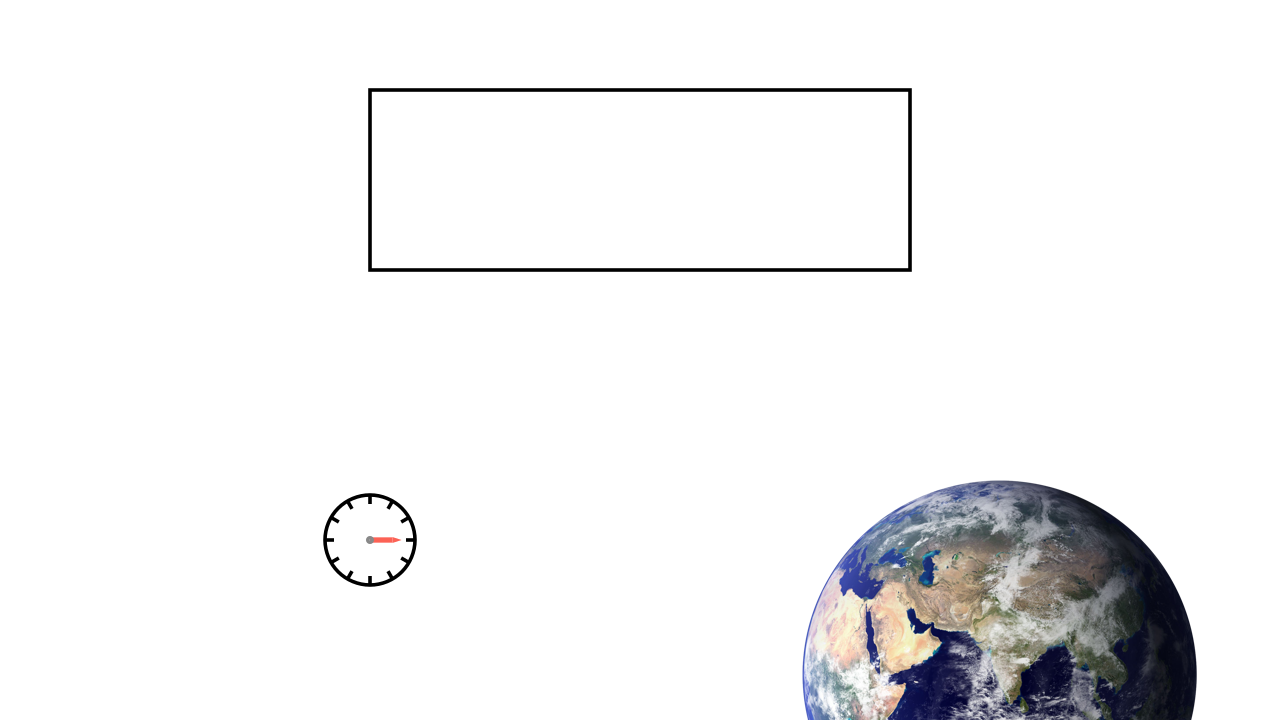

In [101]:
%%manim -qm --fps 60 $video_scene


class srt_Scene(Scene):
	def construct(self):
		self.camera.background_color = WHITE

		CVC = Text('CVC', font_size = 12, weight = BOLD, color = WHITE, font = 'Latin Modern Sans').align_on_border(RIGHT + DOWN, buff = 0.2)
		self.add(CVC)


		clock = Clock(clock_center = np.array([-3, -2, 0]), clock_radius = 0.5)
		clock_time = clock.get_time(15)
		self.add(clock, clock_time)

		spaceship = SpaceShip(ship_center = np.array([0, 2, 0]))
		self.add(spaceship)

		earth = Earth(earth_center = np.array([4, -3.5, 0]))
		self.add(earth)